# СберАвтоподписка. Модель для предсказания целевого действия

Задача: по данным о визите (откуда пришел пользователь, с какого устройства, из какого города) предсказать, совершит ли он целевое действие: оставит заявку, закажет звонок и т.д. Метрика ROC-AUC, ориентир из методички около 0.65.

Здесь я сравниваю модели и смотрю, какие признаки на них влияют. Обучение итоговой модели вынесено в `pipeline.py`, сервис в `main.py` (как запускать, написано в README.md).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [2]:
sessions = pd.read_csv('data/ga_sessions.csv', dtype=str)
target = pd.read_csv('data/target.csv', dtype={'session_id': str})

# как и в EDA, оставляем только визиты, по которым есть события
df = sessions.merge(target[['session_id', 'target']], on='session_id')
print(df.shape)
print('доля целевых визитов:', round(df['target'].mean(), 4))

(1732266, 19)
доля целевых визитов: 0.029


В target.csv есть еще hits_count (сколько событий было в визите). В модель его не беру: он известен только после окончания визита, и с ним модель фактически подсматривала бы ответ. По условию сервис получает только атрибуты визита: utm_*, device_*, geo_*, дату, время и номер визита.

## Подготовка признаков

Что делаю с признаками (часть уже была в EDA):
- '(not set)' считаю пропуском;
- device_os восстанавливаю по бренду: Apple это iOS, остальные телефоны и планшеты Android;
- device_model не беру, он почти весь пустой;
- из даты и времени достаю час и день недели (в EDA конверсия от них зависела);
- разрешение экрана делю на ширину и высоту, странные значения делаю пропуском;
- добавляю флаги, которые понятны маркетологу: органический трафик, реклама в соцсетях, Москва и Петербург.

Такая же функция есть в `pipeline.py`, чтобы сервис готовил данные точно так же (там только нет флагов, которые в итоге не вошли в модель, об этом ниже).

In [3]:
# источники из соцсетей, список из методички
SOCIAL = ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',
          'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm']

CAT_FEATURES = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
                'device_category', 'device_os', 'device_brand', 'device_browser', 'geo_country', 'geo_city']
NUM_FEATURES = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height',
                'is_organic', 'is_social', 'is_moscow_spb']


def prepare(df):
    df = df.copy()
    df = df.replace('(not set)', np.nan)

    # device_os часто пустой, но его можно восстановить по бренду
    df.loc[df['device_os'].isna() & (df['device_brand'] == 'Apple'), 'device_os'] = 'iOS'
    df.loc[df['device_os'].isna() & df['device_brand'].notna() & (df['device_brand'] != 'Apple')
           & df['device_category'].isin(['mobile', 'tablet']), 'device_os'] = 'Android'
    df[CAT_FEATURES] = df[CAT_FEATURES].fillna('other')

    df['visit_number'] = pd.to_numeric(df['visit_number'])
    df['visit_hour'] = pd.to_datetime(df['visit_time'], format='%H:%M:%S').dt.hour
    df['visit_weekday'] = pd.to_datetime(df['visit_date']).dt.day_of_week

    # разрешение экрана в виде строки '360x720' делим на ширину и высоту
    res = df['device_screen_resolution'].astype(str).str.split('x', expand=True).reindex(columns=[0, 1])
    df['screen_width'] = pd.to_numeric(res[0], errors='coerce')
    df['screen_height'] = pd.to_numeric(res[1], errors='coerce')
    bad = ((df['screen_width'] < 100) | (df['screen_height'] < 100)
           | (df['screen_width'] > 8000) | (df['screen_height'] > 8000))
    df.loc[bad, ['screen_width', 'screen_height']] = np.nan

    df['is_organic'] = df['utm_medium'].isin(['organic', 'referral', '(none)']).astype(int)
    df['is_social'] = df['utm_source'].isin(SOCIAL).astype(int)
    df['is_moscow_spb'] = df['geo_city'].isin(['Moscow', 'Saint Petersburg']).astype(int)
    return df[CAT_FEATURES + NUM_FEATURES]


X = prepare(df)
y = df['target'].values
X.head()

,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_browser,geo_country,geo_city,visit_number,visit_hour,visit_weekday,screen_width,screen_height,is_organic,is_social,is_moscow_spb
0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Zlatoust,1,14,2,360.0,720.0,0,0,0
1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,Samsung Internet,Russia,Moscow,1,8,6,385.0,854.0,0,1,1
2,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Krasnoyarsk,1,2,1,360.0,720.0,0,0,0
3,kjsLglQLzykiRbcDiGcD,cpc,other,NOBKLgtuvqYWkXQHeYWM,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,1,5,5,393.0,786.0,0,0,1
4,kjsLglQLzykiRbcDiGcD,cpc,other,other,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,2,5,5,393.0,786.0,0,0,1


In [4]:
X[CAT_FEATURES].nunique().sort_values()

device_category       3
device_os            13
utm_medium           55
device_browser       55
geo_country         159
device_brand        200
utm_source          281
utm_adcontent       281
utm_campaign        407
utm_keyword        1193
geo_city           2389
dtype: int64

In [5]:
for col in ['utm_keyword', 'geo_city', 'utm_campaign', 'device_brand']:
    counts = X[col].value_counts()
    frequent = counts[counts >= 100]
    print(f'{col}: значений {len(counts)}, встречаются 100+ раз: {len(frequent)}, '
          f'они покрывают {frequent.sum() / len(X):.1%} визитов')

utm_keyword: значений 1193, встречаются 100+ раз: 209, они покрывают 99.2% визитов
geo_city: значений 2389, встречаются 100+ раз: 330, они покрывают 98.9% визитов
utm_campaign: значений 407, встречаются 100+ раз: 188, они покрывают 99.7% визитов


device_brand: значений 200, встречаются 100+ раз: 47, они покрывают 99.9% визитов


Почти все значения встречаются редко. Например, из 2389 городов только 330 встречаются хотя бы 100 раз, но на них приходится 98.9% визитов. С ключевыми словами так же: 209 из 1193 покрывают 99.2% визитов. Поэтому при кодировании все значения, которые встречаются меньше 100 раз, объединяю в одну группу. Так модель не будет запоминать единичные визиты, и признаков становится намного меньше.

## Насколько признаки зависят друг от друга

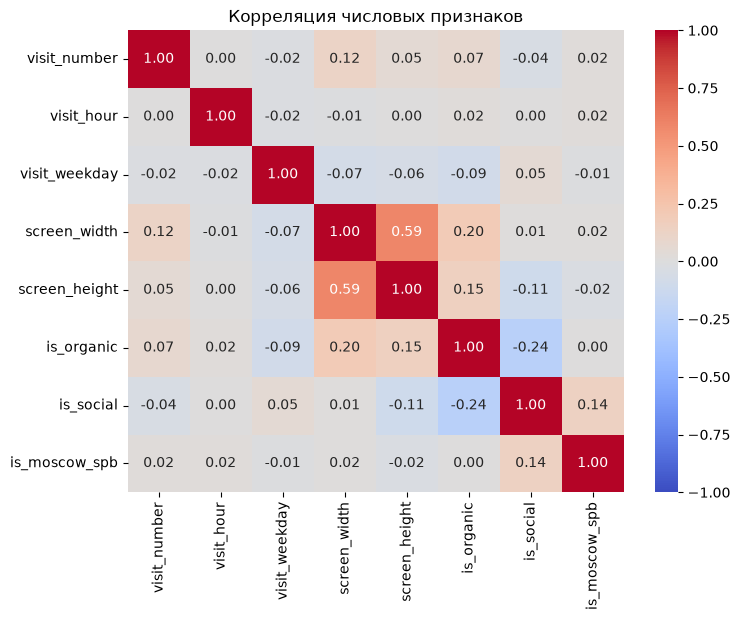

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(X[NUM_FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляция числовых признаков')
plt.show()

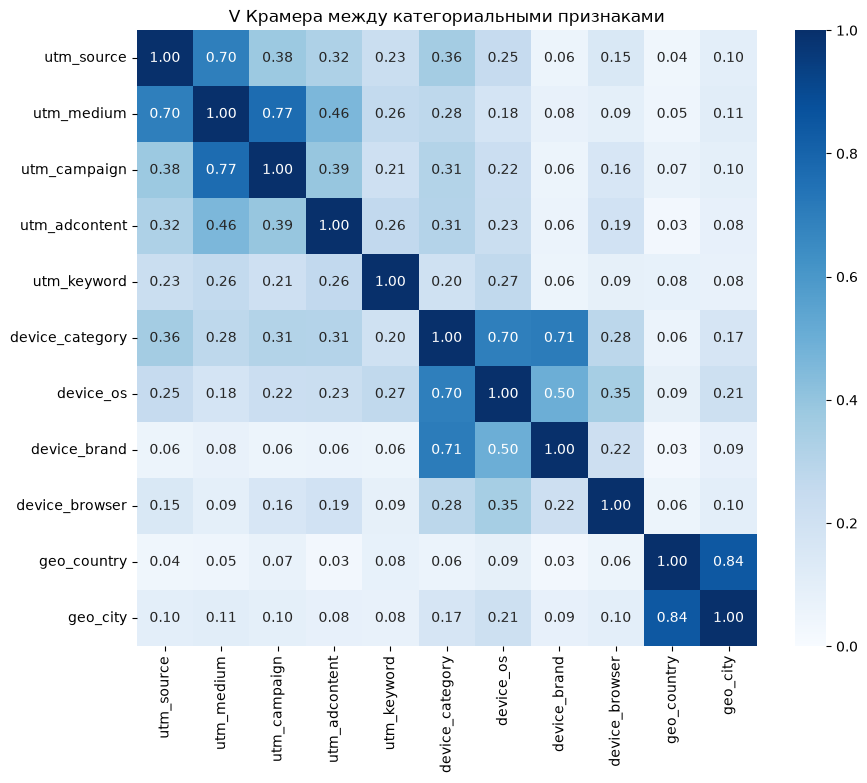

In [7]:
# для категориальных признаков корреляция не считается, вместо нее V Крамера (от 0 до 1)
def cramers_v(a, b):
    table = pd.crosstab(a, b).values
    n = table.sum()
    expected = table.sum(axis=1, keepdims=True) * table.sum(axis=0, keepdims=True) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / n / (min(table.shape) - 1))


sample = X.sample(300_000, random_state=42)
cramers = pd.DataFrame(index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for a in CAT_FEATURES:
    for b in CAT_FEATURES:
        cramers.loc[a, b] = 1.0 if a == b else cramers_v(sample[a], sample[b])

plt.figure(figsize=(10, 8))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('V Крамера между категориальными признаками')
plt.show()

Что видно:
- из числовых признаков заметно связаны только ширина и высота экрана (0.59), остальные почти не коррелируют;
- флаги is_organic, is_social и is_moscow_spb с числовыми признаками связаны слабо, но они целиком вычисляются из utm_medium, utm_source и geo_city, то есть по сути дублируют категориальные признаки;
- среди категориальных сильно связаны utm_medium с utm_campaign (0.77) и с utm_source (0.70): у каждой кампании свой тип трафика. geo_country и geo_city (0.84) почти дублируют друг друга, потому что почти все визиты из России. device_category связан с device_brand и device_os (0.70 и 0.71).

Для логистической регрессии такие зависимости мешают, коэффициенты становятся неустойчивыми. Деревьям в бустинге это не так страшно, но лишние признаки все равно проверю ниже через важность признаков.

## Разбиение на выборки

У одного клиента бывает несколько визитов, и они очень похожи (тот же телефон, тот же город). Если визиты одного клиента попадут и в обучение, и в тест, оценка получится завышенной. Поэтому делю по client_id: 60% обучение, 20% валидация (на ней подбираю параметры и порог), 20% тест (на него смотрю один раз в конце).

In [8]:
groups = df['client_id'].values
train_idx, rest_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.4, random_state=42).split(X, y, groups))
valid_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
                           .split(rest_idx, groups=groups[rest_idx]))
valid_idx, test_idx = rest_idx[valid_pos], rest_idx[test_pos]

X_train, y_train = X.iloc[train_idx], y[train_idx]
X_valid, y_valid = X.iloc[valid_idx], y[valid_idx]
X_test, y_test = X.iloc[test_idx], y[test_idx]

print('общих клиентов в train и test:', len(set(groups[train_idx]) & set(groups[test_idx])))
pd.DataFrame({'визитов': [len(y_train), len(y_valid), len(y_test)],
              'доля целевых': [y_train.mean(), y_valid.mean(), y_test.mean()]},
             index=['train', 'valid', 'test']).round(4)

общих клиентов в train и test: 0


,визитов,доля целевых
train,1038908,0.0288
valid,347870,0.0295
test,345488,0.0293


## Бейзлайн

Самый простой вариант, который можно сделать без модели: посчитать на обучающей выборке конверсию по каждому источнику трафика (utm_source) и считать, что у визита с хорошего источника шанс выше. С этим и буду сравнивать модели.

In [9]:
results = {}

source_cr = pd.Series(y_train).groupby(X_train['utm_source'].values).mean()


def baseline_proba(X_):
    return X_['utm_source'].map(source_cr).fillna(y_train.mean()).values


results['бейзлайн (конверсия utm_source)'] = {
    'valid': roc_auc_score(y_valid, baseline_proba(X_valid)),
    'test': roc_auc_score(y_test, baseline_proba(X_test))}
results

{'бейзлайн (конверсия utm_source)': {'valid': 0.6226112970043807,
  'test': 0.6123233091919542}}

## Логистическая регрессия

Категориальные признаки кодирую через OneHotEncoder (редкие значения в одну колонку), числовые заполняю медианой и масштабирую.

In [10]:
logreg = Pipeline([
    ('prep', ColumnTransformer([
        ('cat', OneHotEncoder(min_frequency=100, handle_unknown='infrequent_if_exist'), CAT_FEATURES),
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM_FEATURES),
    ])),
    ('model', LogisticRegression(max_iter=1000)),
])

start = time.time()
logreg.fit(X_train, y_train)
print(f'обучение: {time.time() - start:.0f} с, признаков после кодирования: {logreg[0].transform(X_train[:5]).shape[1]}')

results['логистическая регрессия'] = {
    'valid': roc_auc_score(y_valid, logreg.predict_proba(X_valid)[:, 1]),
    'test': roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1])}
pd.DataFrame(results).T.round(4)

обучение: 7 с, признаков после кодирования: 857


,valid,test
бейзлайн (конверсия utm_source),0.6226,0.6123
логистическая регрессия,0.6816,0.6746


## Градиентный бустинг

Беру HistGradientBoostingClassifier из sklearn. Он быстро учится на миллионе строк, сам работает с категориальными признаками (не нужно делать тысячи dummy-колонок), с пропусками и с нелинейными зависимостями, например конверсия по часу или номеру визита меняется не по прямой.

Категории перевожу в номера через OrdinalEncoder, редкие (меньше 100 визитов) объединяются в одну, а значения, которых не было в обучении, модель считает пропуском.

In [11]:
def make_model(num_features=NUM_FEATURES, **params):
    encoder = ColumnTransformer([
        ('cat', OrdinalEncoder(min_frequency=100, max_categories=250,
                               handle_unknown='use_encoded_value', unknown_value=-1), CAT_FEATURES),
        ('num', 'passthrough', num_features),
    ], verbose_feature_names_out=False).set_output(transform='pandas')
    classifier = HistGradientBoostingClassifier(categorical_features=CAT_FEATURES, early_stopping=False,
                                                random_state=42, **params)
    return Pipeline([('encoder', encoder), ('classifier', classifier)])


# подбор параметров: несколько вариантов, смотрю ROC-AUC на валидации
param_grid = [
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'l2_regularization': 0.0},
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 500, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 500, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 1000, 'l2_regularization': 1.0},
    {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'l2_regularization': 0.0},
    {'learning_rate': 0.1, 'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'l2_regularization': 1.0},
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 0.0},
]

tuning = []
for params in param_grid:
    start = time.time()
    model = make_model(**params)
    model.fit(X_train, y_train)
    tuning.append({**params, 'roc_auc_valid': roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1]),
                   'время, с': round(time.time() - start)})

tuning = pd.DataFrame(tuning)
tuning.round(4)

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,roc_auc_valid,"время, с"
0,0.10,200,31,200,0.0,0.6929,14
1,0.10,200,63,500,1.0,0.6902,20
2,0.05,400,63,500,1.0,0.6900,20
3,0.05,400,127,1000,1.0,0.6845,28
4,0.10,300,15,200,0.0,0.6935,11
5,0.10,400,31,200,1.0,0.6889,15
6,0.10,200,31,50,0.0,0.6934,12


Разница между вариантами небольшая. Лучше всего получились модели с небольшими деревьями (15-31 лист) и шагом 0.1, а с большими деревьями (127 листьев) качество хуже: сигнал в данных слабый, и большие деревья начинают подстраиваться под шум. Беру лучший вариант: 15 листьев, 300 деревьев, шаг 0.1. Каждый вариант учится 10-30 секунд, так что модель легко переобучать.

In [12]:
best_params = param_grid[tuning['roc_auc_valid'].idxmax()]
print(best_params)

model = make_model(**best_params)
model.fit(X_train, y_train)
auc_full = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
print('ROC-AUC на валидации:', round(auc_full, 4))

{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'l2_regularization': 0.0}


ROC-AUC на валидации: 0.6935


## Что дают новые признаки

Проверка: обучаю тот же бустинг только на исходных категориальных признаках и номере визита, без часа, дня недели, размеров экрана и флагов.

In [13]:
model_base = make_model(['visit_number'], **best_params)
model_base.fit(X_train, y_train)
print('без новых признаков:', round(roc_auc_score(y_valid, model_base.predict_proba(X_valid)[:, 1]), 4))
print('с новыми признаками:', round(auc_full, 4))

без новых признаков: 0.6924
с новыми признаками: 0.6935


Новые признаки дают небольшой прирост: 0.6935 против 0.6924. Основное модель берет из исходных utm-меток, города и номера визита. Но прирост есть, и по скорости признаки ничего не стоят, поэтому оставляю их.

## Какие признаки важны

Использую permutation importance: перемешиваю значения одного признака в тесте и смотрю, насколько падает ROC-AUC. Чем сильнее падает, тем больше модель опирается на этот признак.

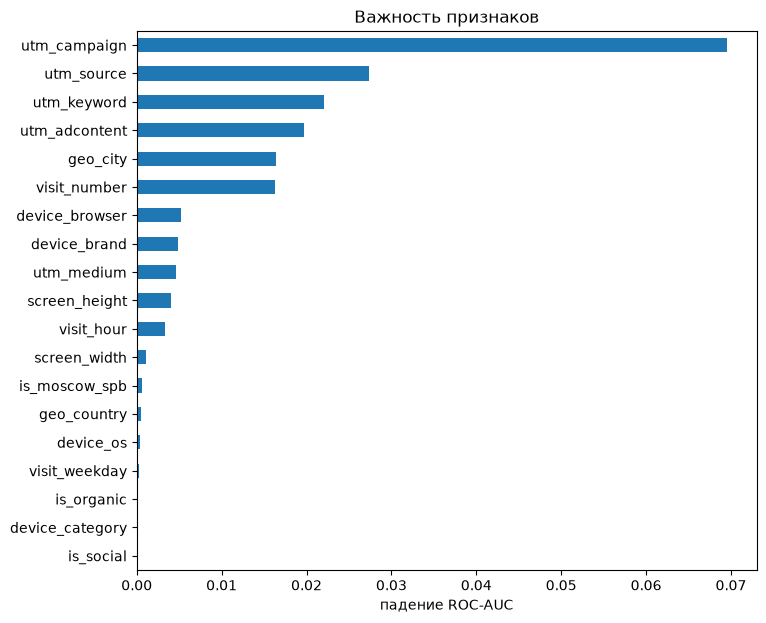

utm_campaign       0.0696
utm_source         0.0273
utm_keyword        0.0220
utm_adcontent      0.0196
geo_city           0.0164
visit_number       0.0162
device_browser     0.0053
device_brand       0.0049
utm_medium         0.0046
screen_height      0.0041
visit_hour         0.0033
screen_width       0.0010
is_moscow_spb      0.0006
geo_country        0.0005
device_os          0.0004
visit_weekday      0.0003
is_organic         0.0000
device_category    0.0000
is_social          0.0000
dtype: float64

In [14]:
# считаю на валидации, тест пока не трогаю
sample_idx = np.random.RandomState(42).choice(len(X_valid), 200_000, replace=False)
imp = permutation_importance(model, X_valid.iloc[sample_idx], y_valid[sample_idx], scoring='roc_auc',
                             n_repeats=3, random_state=42, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=X_valid.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind='barh')
plt.xlabel('падение ROC-AUC')
plt.title('Важность признаков')
plt.show()
importance.sort_values(ascending=False).round(4)

Самый важный признак utm_campaign: если его перемешать, ROC-AUC падает на 0.07. Дальше идут остальные utm-метки (источник, ключевое слово, объявление), город и номер визита. То есть шанс на целевое действие в первую очередь зависит от того, с какой рекламы пришел человек и в который раз он на сайте. Устройство и время визита влияют слабо.

Флаги is_organic, is_social и is_moscow_spb модели не нужны, их важность около нуля: то же самое она уже знает из utm_medium, utm_source и geo_city. У device_category тоже почти ноль, потому что тип устройства понятен по бренду, ОС и размеру экрана, но это исходный атрибут визита, его оставляю. Проверю, что будет, если убрать флаги.

In [15]:
# флаги is_* полностью определяются utm_medium, utm_source и geo_city, бустинг и так видит эту информацию
FINAL_NUM = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height']
FINAL_FEATURES = CAT_FEATURES + FINAL_NUM

model = make_model(FINAL_NUM, **best_params)
model.fit(X_train[FINAL_FEATURES], y_train)
print('без флагов:', round(roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]), 4))
print('с флагами: ', round(auc_full, 4))

без флагов: 0.6942
с флагами:  0.6935


Без флагов качество даже чуть выше (0.6942 против 0.6935), поэтому в итоговой модели их нет. Остаются 11 категориальных признаков и 5 числовых: номер визита, час, день недели, ширина и высота экрана. Все они понятны без объяснений: откуда пришел пользователь, с какого устройства, из какого города, в который раз и в какое время.

## Сравнение на тестовой выборке

In [16]:
results['градиентный бустинг'] = {
    'valid': roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]),
    'test': roc_auc_score(y_test, model.predict_proba(X_test[FINAL_FEATURES])[:, 1])}
pd.DataFrame(results).T.round(4)

,valid,test
бейзлайн (конверсия utm_source),0.6226,0.6123
логистическая регрессия,0.6816,0.6746
градиентный бустинг,0.6942,0.6962


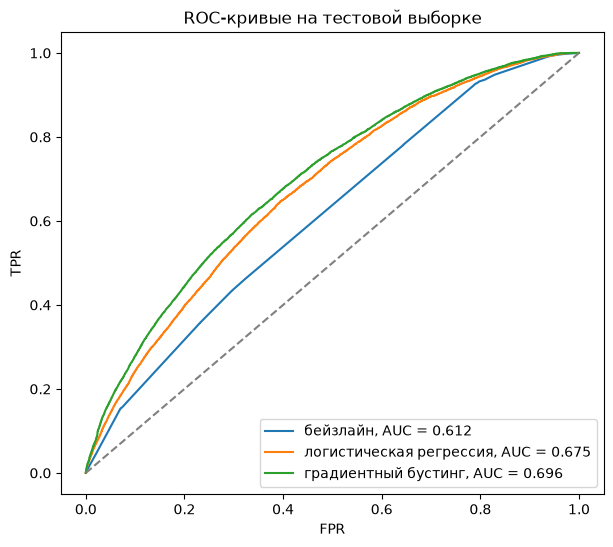

In [17]:
plt.figure(figsize=(7, 6))
for name, proba in [('бейзлайн', baseline_proba(X_test)),
                    ('логистическая регрессия', logreg.predict_proba(X_test)[:, 1]),
                    ('градиентный бустинг', model.predict_proba(X_test[FINAL_FEATURES])[:, 1])]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name}, AUC = {roc_auc_score(y_test, proba):.3f}')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривые на тестовой выборке')
plt.legend()
plt.show()

На тесте бустинг дает ROC-AUC 0.696. Это выше ориентира из методички (0.65), выше бейзлайна по источнику трафика (0.612) и выше логистической регрессии (0.675). На валидации и на тесте результат почти одинаковый, значит модель не подстроилась под валидацию, на которой я подбирал параметры.

## Порог

Сервис должен отдавать 0 или 1, а модель выдает вероятность. Целевых визитов всего 3%, поэтому стандартный порог 0.5 почти никогда не срабатывает. Порог выбираю на валидации по максимуму F1.

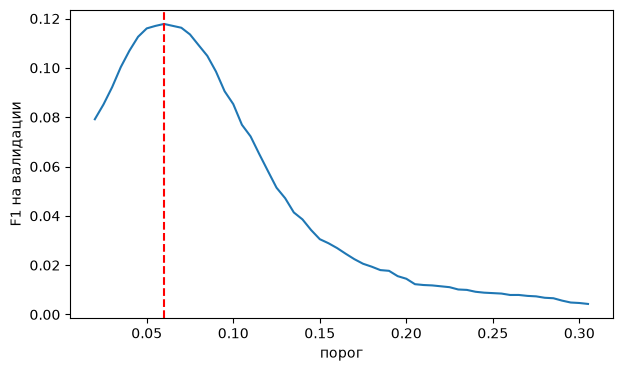

порог: 0.06


In [18]:
valid_proba = model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]
thresholds = np.round(np.arange(0.02, 0.31, 0.005), 3)
f1s = [f1_score(y_valid, (valid_proba >= t).astype(int)) for t in thresholds]
threshold = thresholds[int(np.argmax(f1s))]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1s)
plt.axvline(threshold, color='red', linestyle='--')
plt.xlabel('порог')
plt.ylabel('F1 на валидации')
plt.show()
print('порог:', threshold)

precision: 0.085
recall:    0.223
F1:        0.123
доля визитов, где модель ставит 1: 0.077


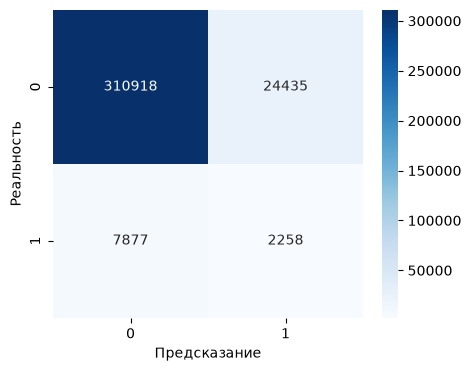

In [19]:
test_proba = model.predict_proba(X_test[FINAL_FEATURES])[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print(f'precision: {precision_score(y_test, test_pred):.3f}')
print(f'recall:    {recall_score(y_test, test_pred):.3f}')
print(f'F1:        {f1_score(y_test, test_pred):.3f}')
print(f'доля визитов, где модель ставит 1: {test_pred.mean():.3f}')

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Предсказание')
plt.ylabel('Реальность')
plt.show()

При пороге 0.06 модель ставит 1 примерно 7.7% визитов. Из них целевое действие совершают 8.5% (precision), это почти в 3 раза больше средней конверсии 2.9%. При этом модель находит 22% всех целевых визитов (recall). Сильно лучше по одной строке визита сделать сложно: люди с одной и той же рекламы и с одинаковыми телефонами ведут себя по-разному. Если бизнесу важнее найти больше целевых визитов, порог можно понизить: recall вырастет, precision упадет.

## Как модель видит разные группы визитов

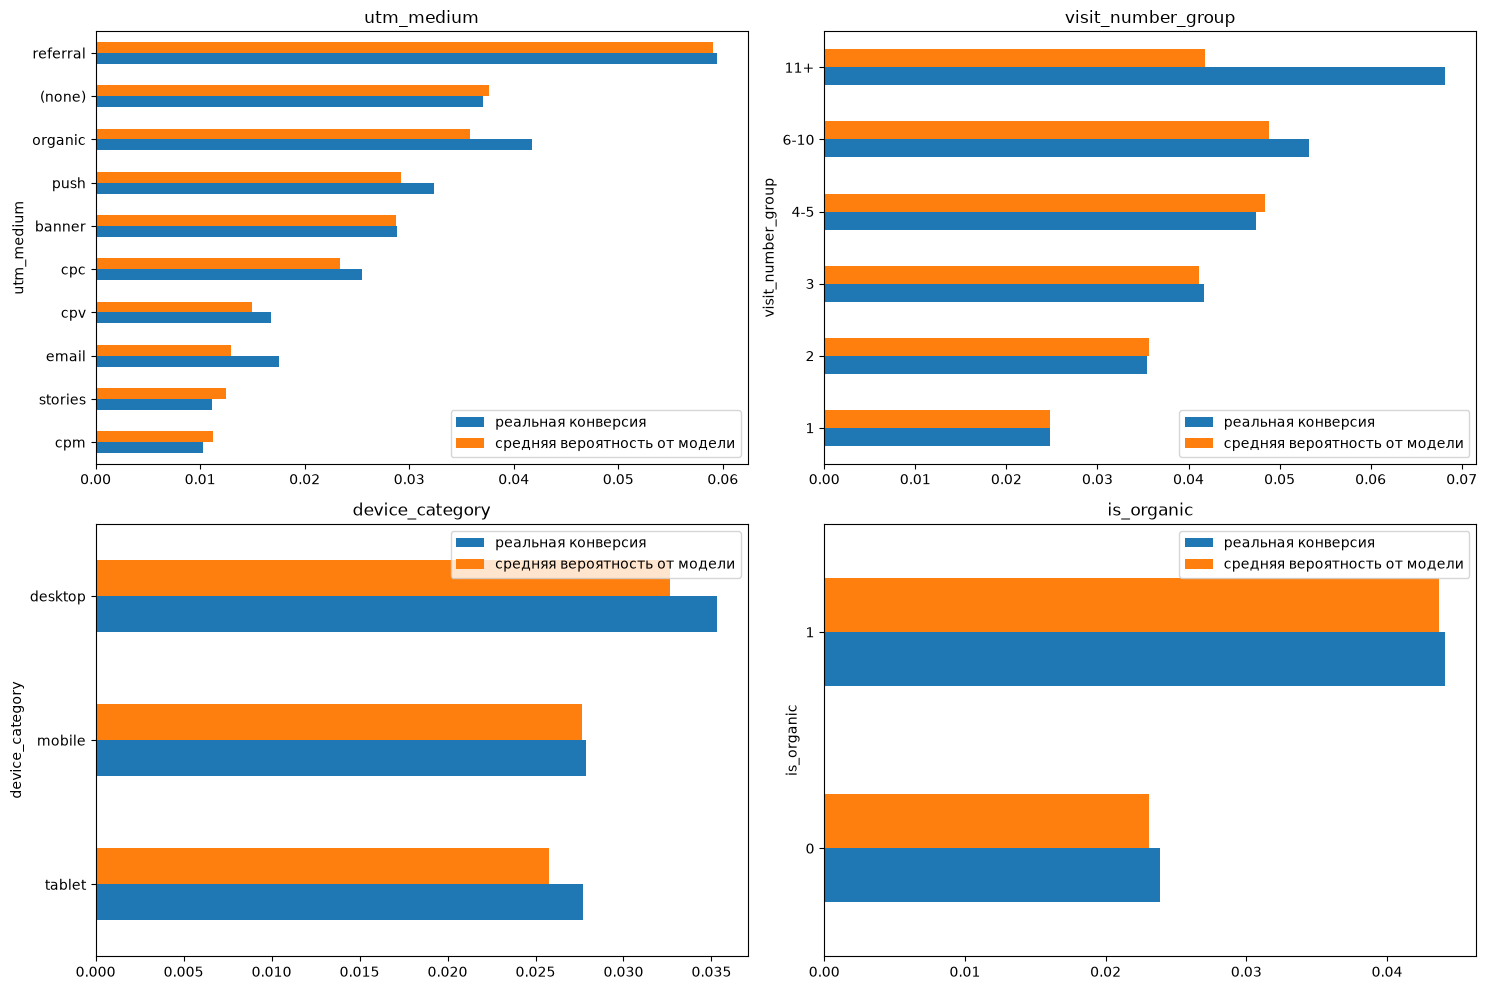

In [20]:
# как меняется предсказанная вероятность в зависимости от признаков, понятных маркетологу
X_show = X_test.copy()
X_show['target'] = y_test
X_show['proba'] = test_proba
X_show['visit_number_group'] = pd.cut(X_show['visit_number'], [0, 1, 2, 3, 5, 10, 10000],
                                      labels=['1', '2', '3', '4-5', '6-10', '11+'])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flatten(), ['utm_medium', 'visit_number_group', 'device_category', 'is_organic']):
    top = X_show[col].value_counts().index[:10]
    part = X_show[X_show[col].isin(top)].groupby(col, observed=True)[['target', 'proba']].mean()
    if col != 'visit_number_group':
        part = part.sort_values('proba')
    part.plot(kind='barh', ax=ax)
    ax.set_title(col)
    ax.legend(['реальная конверсия', 'средняя вероятность от модели'], loc='best')
plt.tight_layout()
plt.show()

Средняя вероятность от модели почти совпадает с реальной конверсией по группам, то есть модель не только правильно ранжирует визиты, но и дает правдоподобные вероятности. Что из этого можно сказать маркетологу:
- лучше всего конвертируются переходы с других сайтов (referral, около 6%) и органический трафик в целом (4.4% против 2.4% у платного);
- хуже всего медийная реклама cpm и stories, около 1%;
- чем больше раз человек уже был на сайте, тем выше шанс заявки: 2.5% на первом визите и около 5% с четвертого. Значит, реклама на тех, кто уже заходил на сайт, должна окупаться лучше, чем привлечение новых людей;
- с компьютера конвертируются чуть лучше, чем с телефона и планшета.

Для пользователей с 11 и больше визитами модель занижает вероятность (4.2% против 6.8%), таких визитов мало, и модель их недооценивает.